In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

Load Dataset

In [2]:
df=pd.read_csv("Advertising.csv")

In [3]:
#Remove Unnecessary Index Column If It Exists
if "Unnamed: 0" in df.columns:
    df=df.drop(columns=["Unnamed: 0"])

In [4]:
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


Understand The Dataset

In [5]:
print("Dataset Shaped:", df.shape)

Dataset Shaped: (200, 4)


In [6]:
print("dataset Information:")
df.info()

dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [7]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


In [8]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [9]:
print("Statistical Summary:")
print(df.describe())

Statistical Summary:
               TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   15.130500
std     85.854236   14.846809   21.778621    5.283892
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   11.000000
50%    149.750000   22.900000   25.750000   16.000000
75%    218.825000   36.525000   45.100000   19.050000
max    296.400000   49.600000  114.000000   27.000000


Data Cleaning

In [10]:
df=df.drop_duplicates()

#handle Missing Values Using Median
for column in df.columns:
    df[column]=df[column].fillna(df[column].median())

print("Missing Values After Clearning:")
print(df.isnull().sum())

Missing Values After Clearning:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


In [11]:
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


Exploratory Data Analysis

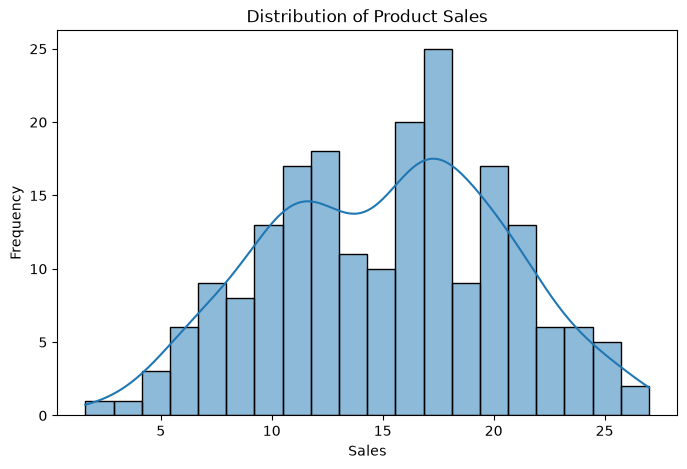

In [12]:
#Visualize the Distribution Of Sales
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Sales",
    bins=20,
    kde=True
)

plt.title("Distribution of Product Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

Sales vs TV Advertising

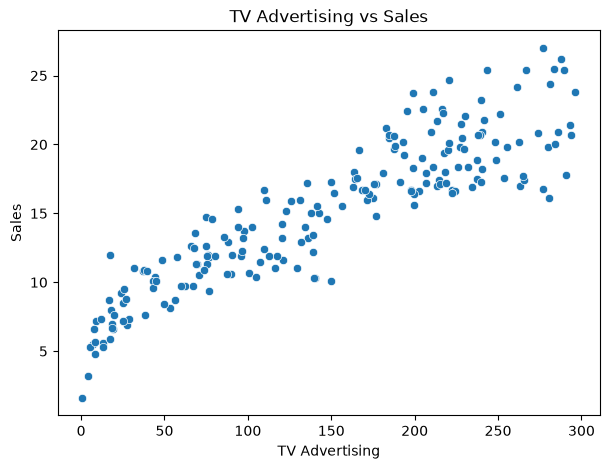

In [13]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df,
    x="TV",
    y="Sales",
)

plt.title("TV Advertising vs Sales")
plt.xlabel("TV Advertising")
plt.ylabel("Sales")

plt.show()

Sales vs Radio Advertising

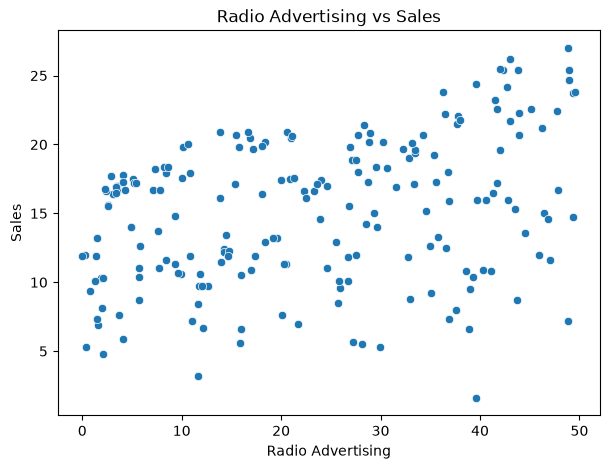

In [14]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df,
    x="Radio",
    y="Sales"
)

plt.title("Radio Advertising vs Sales")
plt.xlabel("Radio Advertising")
plt.ylabel("Sales")

plt.show()

Sales vs Newspaper Advertising

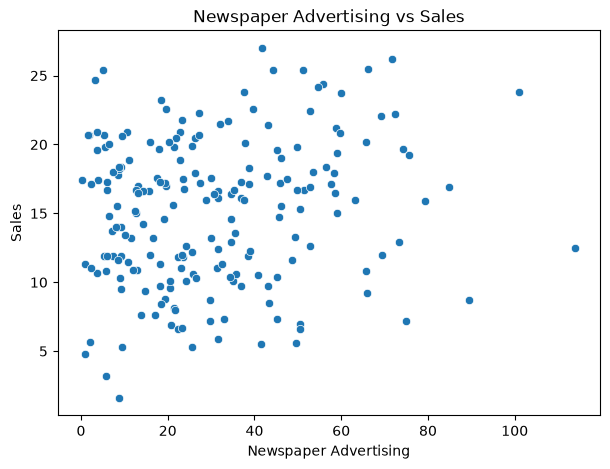

In [15]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df,
    x="Newspaper",
    y="Sales"
)

plt.title("Newspaper Advertising vs Sales")
plt.xlabel("Newspaper Advertising")
plt.ylabel("Sales")

plt.show()

Correlation Heatmap

<Axes: >

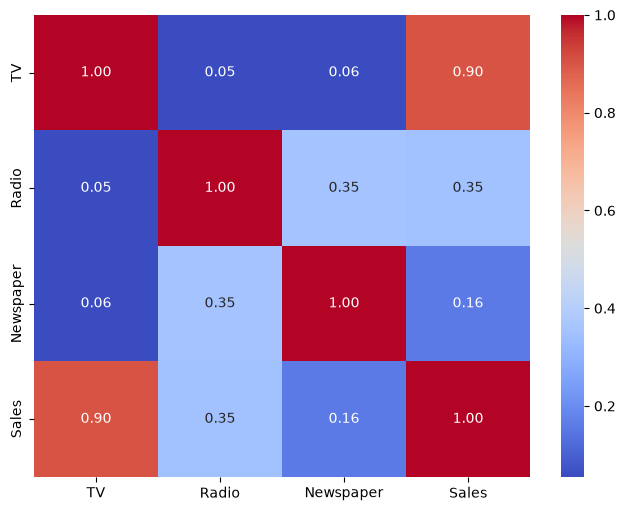

In [16]:
correlation=df.corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)


Data Preparation

In [17]:
#Input Features
X=df[["TV","Radio", "Newspaper"]]

#Target Variable
y=df["Sales"]

#Split Dataset Into Training and Testing Sets
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (160, 3)
Testing Data Shape: (40, 3)


Train Linear Regression Model

In [18]:
#Linear Regression Model
linear_model=LinearRegression()

#Model Training
linear_model.fit(X_train, y_train)

#Make Predictions
linear_predictions=linear_model.predict(X_test)

print("Linear Regression Modek Trained Successfully!")

Linear Regression Modek Trained Successfully!


Random Forest Regressor

In [19]:
#Creating Random Forest Model
random_forest_model=RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

#Model Training
random_forest_model.fit(X_train, y_train)

#Make Predictions
rf_predictions=random_forest_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


Model Evaluation

In [20]:
def evaluate_model(actual, predicted):
    mae=mean_absolute_error(actual, predicted)
    rmse=np.sqrt(
        mean_squared_error(actual, predicted)
    )
    r2=r2_score(actual, predicted)

    return mae, rmse, r2

#Evaluate Linear Regression
linear_mae, linear_rmse, linear_r2=evaluate_model(
    y_test,
    linear_predictions
)

#Evaluate Random Forest
rf_mae, rf_rmse, rf_r2=evaluate_model(
    y_test,
    rf_predictions
)

#Comparison Table
results=pd.DataFrame({
    "Model":[
        "Linear Regression",
        "Random Forest"
    ],

    "MAE":[
        linear_mae,
        rf_mae
    ],

    "RMSE":[
        linear_rmse,
        rf_rmse
    ],

    "R2 Score":[
        linear_r2,
        rf_r2
    ]
})

print(results)

               Model       MAE      RMSE  R2 Score
0  Linear Regression  1.274826  1.705215  0.905901
1      Random Forest  0.918000  1.198930  0.953483


Compare Model Performance

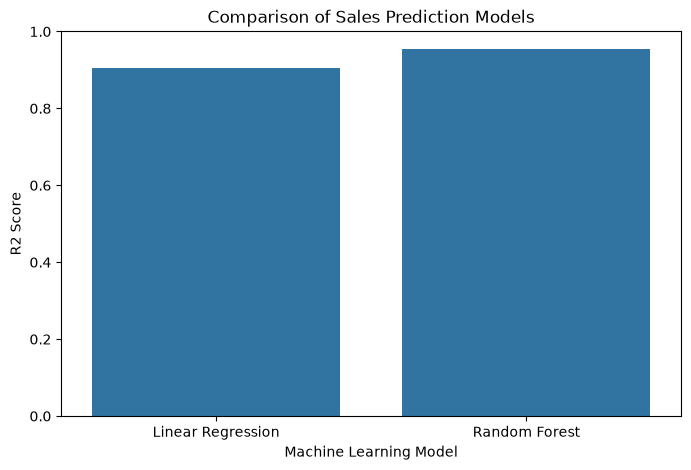

In [21]:
#Compare R2 Score OF Both Models
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score"
)

plt.title("Comparison of Sales Prediction Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("R2 Score")

plt.show()

In [22]:
#Selecting the model with higher R2 Score
if linear_r2 >= rf_r2:

    best_model=linear_model
    best_predictions=linear_predictions
    best_model_name="Linear Regression"

else:
    best_model=random_forest_model
    best_predictions=rf_predictions
    best_model_name="Random Forest"

print("Best Performing Model:", best_model_name)

Best Performing Model: Random Forest


Linear Regression Coefficients

In [23]:
coefficients=pd.DataFrame({
    "Advertising Channel": X.columns,
    "Coefficient": linear_model.coef_
})

#Sort by Absolute Coefficient Value
coefficients["Impact"]=coefficients["Coefficient"].abs()

coefficients=coefficients.sort_values(
    by="Impact",
    ascending=False
)

print(coefficients)

  Advertising Channel  Coefficient    Impact
1               Radio     0.100945  0.100945
0                  TV     0.054509  0.054509
2           Newspaper     0.004337  0.004337


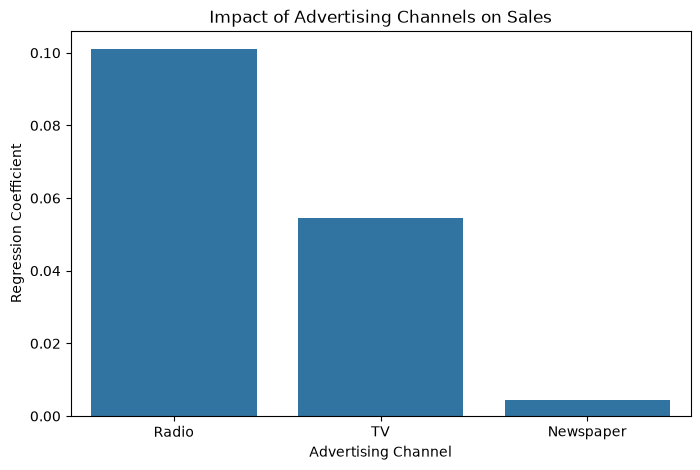

In [24]:
#Ploting Advertising Channel Coefficients
plt.figure(figsize=(8,5))

sns.barplot(
    data=coefficients,
    x="Advertising Channel",
    y="Coefficient"
)

plt.title("Impact of Advertising Channels on Sales")
plt.xlabel("Advertising Channel")
plt.ylabel("Regression Coefficient")

plt.show()

In [25]:
#Identify the most impactful channel
most_impactful_channel=coefficients.iloc[0]["Advertising Channel"]

print(
    "Most Impactful Advertising Channel:",
    most_impactful_channel
)

Most Impactful Advertising Channel: Radio


Random Forest Feature Importance

In [26]:
feature_importance=pd.DataFrame({
    "Advertising Channel": X.columns,
    "Importance": random_forest_model.feature_importances_
})

#Sort Feature Importance
feature_importance=feature_importance.sort_values(
    by="Importance",
    ascending=True
)

print(feature_importance)

  Advertising Channel  Importance
2           Newspaper    0.018003
1               Radio    0.136642
0                  TV    0.845355


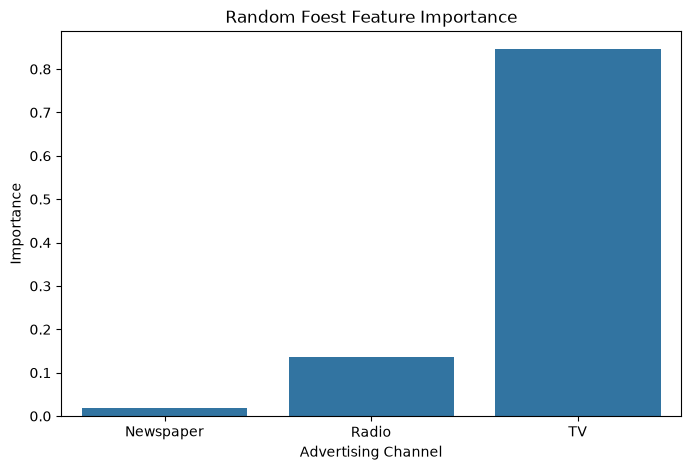

In [27]:
#Visualizing Feature Importance
plt.figure(figsize=(8,5))

sns.barplot(
    data=feature_importance,
    x="Advertising Channel",
    y="Importance"
)

plt.title("Random Foest Feature Importance")
plt.xlabel("Advertising Channel")
plt.ylabel("Importance")

plt.show()

Residual Plot

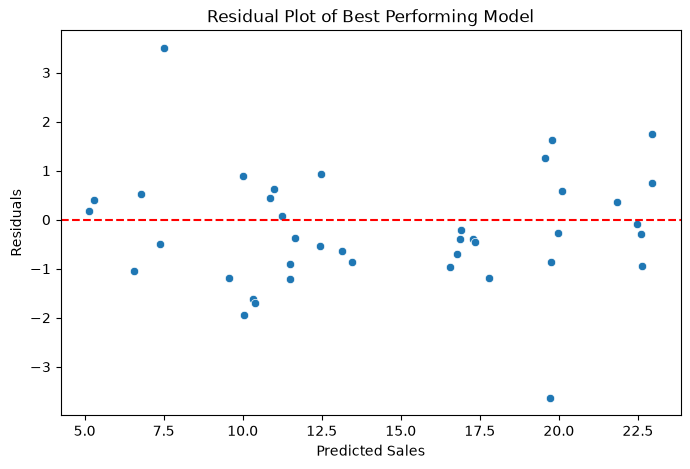

In [28]:
#Calculate Residual
residuals= y_test - best_predictions

#Create Residual Plot
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=best_predictions,
    y=residuals
)

#Adding Horizontal Reference Line At Zero
plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residual Plot of Best Performing Model")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")

plt.show()

Predict Sales for New Advertising Expenditure

In [29]:
#Create Advertising Expenditure Details
new_advertising=pd.DataFrame({
    "TV": [150],
    "Radio": [25],
    "Newspaper": [20]
})

#Predict Product Sales
predicted_sales=best_model.predict(new_advertising)

print(
    "Predicted Sales:",
    round(predicted_sales[0], 2)
)

Predicted Sales: 14.9
